# 01 — Exploring the OpenSky API

**Project:** predicting the remaining flight time of commercial flights from their ADS-B state vectors (position, speed, altitude…).

**Goal of this notebook:** before building a dataset, understand what the OpenSky data looks like, by querying its public REST API. Three endpoints, three questions:

| Section | Endpoint | Question | Access |
|---|---|---|---|
| 1 | `/states/all` | What does an aircraft broadcast, and what does a snapshot of the sky look like? | anonymous |
| 2 | `/states/all`, repeated | Can trajectories be built from successive snapshots? | anonymous |
| 3 | `/flights/all` | What is a "flight" for OpenSky? | OpenSky account |
| 4 | `/tracks/all` | What does a whole flight look like, and how can the remaining time be defined? | OpenSky account |

Section 5 draws the conclusions: what this exploration teaches for the pipeline, and why the next notebooks use OpenSky's **public historical datasets** instead of the REST API.

**Running it.** The API returns live data: each run gives different numbers, and the comments describe the run saved in this notebook. Sections 3 and 4 need an OpenSky API client, whose credentials are read from a `.env` file (`OPENSKY_CLIENT_ID`, `OPENSKY_CLIENT_SECRET`, see `.env.example`).

## 0. Setup

In [1]:
import os
import time
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv

from opensky_eta.config import M_TO_FT, MS_TO_FT_MIN, MS_TO_KT, PROJECT_DIR
from opensky_eta.plotting import set_plot_style

set_plot_style()

API_URL = "https://opensky-network.org/api"
TOKEN_URL = "https://auth.opensky-network.org/auth/realms/opensky-network/protocol/openid-connect/token"

# Fields of a state vector, in the order of the API response
STATE_COLUMNS = [
    "icao24", "callsign", "origin_country", "time_position", "last_contact", "longitude", "latitude",
    "baro_altitude", "on_ground", "velocity", "true_track", "vertical_rate", "sensors", "geo_altitude",
    "squawk", "spi", "position_source",
]


def get_json(endpoint, params=None, headers=None):
    """GET request to the OpenSky REST API, returning the decoded JSON."""
    response = requests.get(f"{API_URL}/{endpoint}", params=params, headers=headers, timeout=60)
    response.raise_for_status()
    return response.json()


def states_to_df(data):
    """One row per aircraft of a /states/all response."""
    return pd.DataFrame(data["states"], columns=STATE_COLUMNS)


def to_utc(timestamp):
    """Unix timestamp(s) -> UTC datetime(s)."""
    return pd.to_datetime(timestamp, unit="s", utc=True)

## 1. A snapshot of the sky: `/states/all`

Without any parameter, this endpoint returns the **current state vector of every aircraft tracked by OpenSky**. A state vector is what an aircraft broadcasts through its ADS-B transponder (position, altitude, speed…), received by the OpenSky network of ground receivers.

In [2]:
snapshot = get_json("states/all")
print(f"Keys of the response: {list(snapshot)}")
print(f"Snapshot time: {to_utc(snapshot['time'])}, {len(snapshot['states']):,} aircraft")
print("First state vector, as returned by the API:")
snapshot["states"][0]

Keys of the response: ['time', 'states']
Snapshot time: 2026-10-12 14:29:44+00:00, 12,358 aircraft
First state vector, as returned by the API:


['39de4f',
 'TVF34TB ',
 'France',
 1791815383,
 1791815383,
 27.8394,
 42.1408,
 8214.36,
 False,
 224.02,
 307.82,
 7.8,
 None,
 8435.34,
 '1000',
 False,
 0]

Each aircraft comes as a list of 17 values, documented by OpenSky:

| Field | Meaning | Unit |
|---|---|---|
| `icao24` | unique address of the transponder (identifies the aircraft) | hexadecimal string |
| `callsign` | flight identifier (e.g. `AFR123`, airline code + flight number) | string |
| `origin_country` | country of registration, deduced from `icao24` | string |
| `time_position` | time of the last position update | Unix seconds |
| `last_contact` | time of the last message of any kind | Unix seconds |
| `longitude`, `latitude` | position | degrees (WGS-84) |
| `baro_altitude` | barometric (pressure) altitude | metres |
| `on_ground` | the aircraft reports being on the ground | boolean |
| `velocity` | ground speed | m/s |
| `true_track` | direction of the movement, clockwise from north | degrees |
| `vertical_rate` | climb (> 0) or descent (< 0) rate | m/s |
| `sensors` | receivers that contributed (only on request) | list |
| `geo_altitude` | geometric (GNSS) altitude | metres |
| `squawk` | code set by the pilot on the transponder | string |
| `spi` | special purpose indicator | boolean |
| `position_source` | origin of the position: 0 = ADS-B, 1 = ASTERIX, 2 = MLAT, 3 = FLARM | integer |

The units are SI (metres, m/s), while aviation uses feet and knots: the next notebooks convert them.

In [3]:
states = states_to_df(snapshot)
display(states.head())

print("Share of missing values per field:")
display(states.isna().mean().sort_values(ascending=False).round(3).to_frame("missing share").T)
print(f"On the ground: {states['on_ground'].mean():.1%} of the aircraft")
print("Position sources:", states["position_source"].value_counts(normalize=True).round(3).to_dict())

,icao24,callsign,origin_country,time_position,last_contact,longitude,latitude,baro_altitude,on_ground,velocity,true_track,vertical_rate,sensors,geo_altitude,squawk,spi,position_source
0,39de4f,TVF34TB,France,1.791815e+09,1791815383,27.8394,42.1408,8214.36,False,224.02,307.82,7.80,None,8435.34,1000,False,0
1,e8027e,LPE2085,Chile,1.791815e+09,1791815330,-76.3623,-6.5703,548.64,False,72.66,349.80,-2.28,None,579.12,NaN,False,0
2,801638,AXB1082,India,1.791815e+09,1791815383,77.0975,28.5643,NaN,True,37.04,106.88,NaN,None,NaN,2654,False,0
3,39de4a,TVF15DN,France,1.791815e+09,1791815384,-0.2042,44.3122,11887.20,False,237.36,215.21,0.00,None,12481.56,7672,False,0
4,aa9321,UAL1777,United States,1.791815e+09,1791815383,-89.9614,42.0590,10363.20,False,233.52,273.66,0.00,None,10835.64,1154,False,0


Share of missing values per field:


,sensors,squawk,geo_altitude,vertical_rate,baro_altitude,time_position,longitude,latitude,velocity,icao24,spi,on_ground,true_track,callsign,last_contact,origin_country,position_source
missing share,1.0,0.423,0.109,0.101,0.099,0.006,0.006,0.006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


On the ground: 9.6% of the aircraft
Position sources: {0: 1.0, 3: 0.0}


- **About 12,000 aircraft are tracked at the same moment**, nearly all through ADS-B (`position_source` = 0).
- **`sensors` is always empty** (it is only filled on request) and **`squawk` is missing for 42 %** of the aircraft: neither is needed.
- **The altitudes and the vertical rate are missing for about 10 % of the aircraft**, about as many as the aircraft on the ground (9.6 %): on the ground, a transponder sends surface positions, without altitude (see the third row above). The position itself is almost always there (0.6 % missing).
- **There is no flight identifier**: a state vector tells which aircraft it is (`icao24`), not which flight it belongs to, nor where the aircraft comes from or goes to.

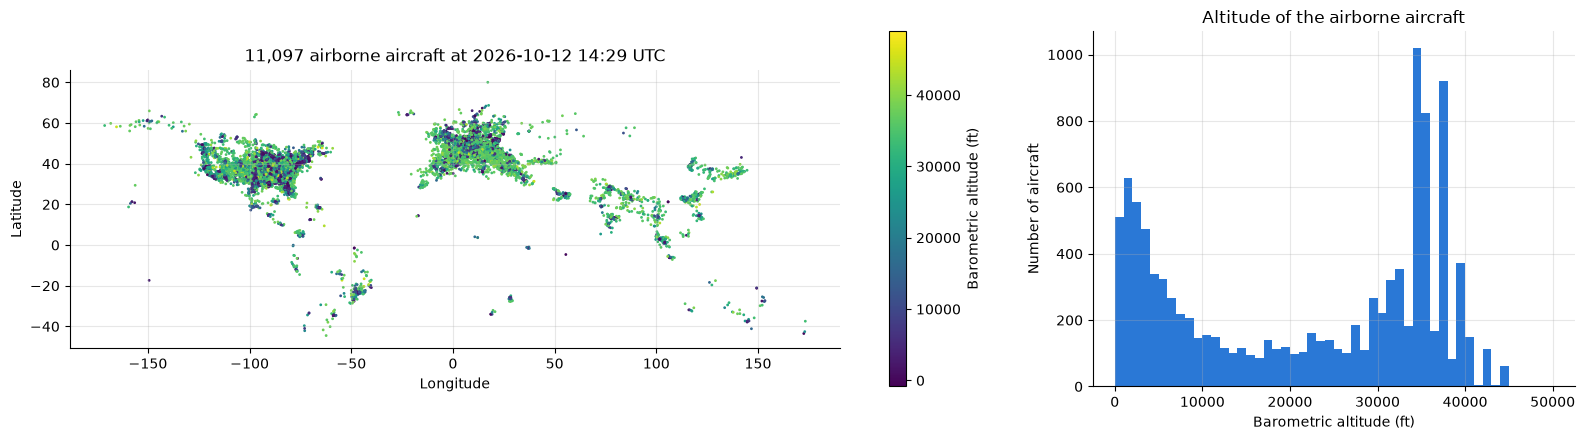

In [4]:
airborne = states[~states["on_ground"]].dropna(subset=["longitude", "latitude", "baro_altitude"])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2, 1]})
points = axes[0].scatter(airborne["longitude"], airborne["latitude"], c=airborne["baro_altitude"] * M_TO_FT,
                         s=1, cmap="viridis")
fig.colorbar(points, ax=axes[0], label="Barometric altitude (ft)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_title(f"{len(airborne):,} airborne aircraft at {to_utc(snapshot['time']):%Y-%m-%d %H:%M} UTC")
axes[0].set_aspect("equal")
axes[1].hist(airborne["baro_altitude"] * M_TO_FT, bins=np.arange(0, 50_001, 1_000))
axes[1].set_xlabel("Barometric altitude (ft)")
axes[1].set_ylabel("Number of aircraft")
axes[1].set_title("Altitude of the airborne aircraft")
plt.tight_layout()
plt.show()

- **The coverage follows the receivers, not the traffic:** North America and Europe are dense, while the oceans and Africa are almost empty, and large parts of Asia and South America are sparse. OpenSky relies on volunteers' ground receivers, which only hear the aircraft within a few hundred kilometres: a flight crossing an ocean disappears for hours.
- **The altitudes show two populations:** a peak around 35,000–38,000 ft, made of narrow bars (airliners in cruise fly at discrete flight levels, every 1,000 ft), and many aircraft below 10,000 ft (climbs, approaches, and light aircraft that never fly higher).

## 2. From snapshots to trajectories

`/states/all` only gives the **present**. A trajectory can be built by asking again and again, and following each aircraft through the successive snapshots: here, 10 requests 10 seconds apart.

In [5]:
N_REQUESTS, WAIT_S = 10, 10

snapshots = []
for i in range(N_REQUESTS):
    data = get_json("states/all")
    snapshots.append(states_to_df(data).assign(snapshot_time=data["time"]))
    if i < N_REQUESTS - 1:
        time.sleep(WAIT_S)
all_states = pd.concat(snapshots, ignore_index=True)

snapshot_times = all_states["snapshot_time"].drop_duplicates().sort_values()
print(f"{N_REQUESTS} requests, {len(snapshot_times)} distinct snapshots; "
      f"seconds between them: {snapshot_times.diff().dropna().astype(int).tolist()}")

10 requests, 10 distinct snapshots; seconds between them: [19, 11, 8, 11, 8, 3, 19, 8, 10]


The API does not answer with the state of the sky at the exact moment of the request, but with its latest snapshot: a new one roughly every 10 seconds, here at irregular intervals (3 to 19 seconds). The sampling rate cannot be chosen.

10,712 aircraft airborne in all the 10 snapshots


,snapshot_time,callsign,latitude,longitude,baro_altitude,velocity,vertical_rate
10121,1791815387,EJA860,36.4568,-86.0661,3756.66,158.84,-10.40
22497,1791815406,EJA860,36.4474,-86.0982,3566.16,153.79,-9.75
34879,1791815417,EJA860,36.4424,-86.1153,3459.48,151.50,-10.40
47271,1791815425,EJA860,36.4384,-86.1287,3368.04,149.88,-10.40
59676,1791815436,EJA860,36.4336,-86.1455,3253.74,148.73,-10.40
72071,1791815444,EJA860,36.4300,-86.1579,3169.92,147.59,-10.40
84461,1791815447,EJA860,36.4286,-86.1627,3139.44,147.11,-10.40
96835,1791815466,EJA860,36.4202,-86.1916,2948.94,144.82,-10.40
109207,1791815474,EJA860,36.4165,-86.2043,2865.12,144.34,-10.08
121582,1791815484,EJA860,36.4133,-86.2153,2796.54,142.71,-9.10


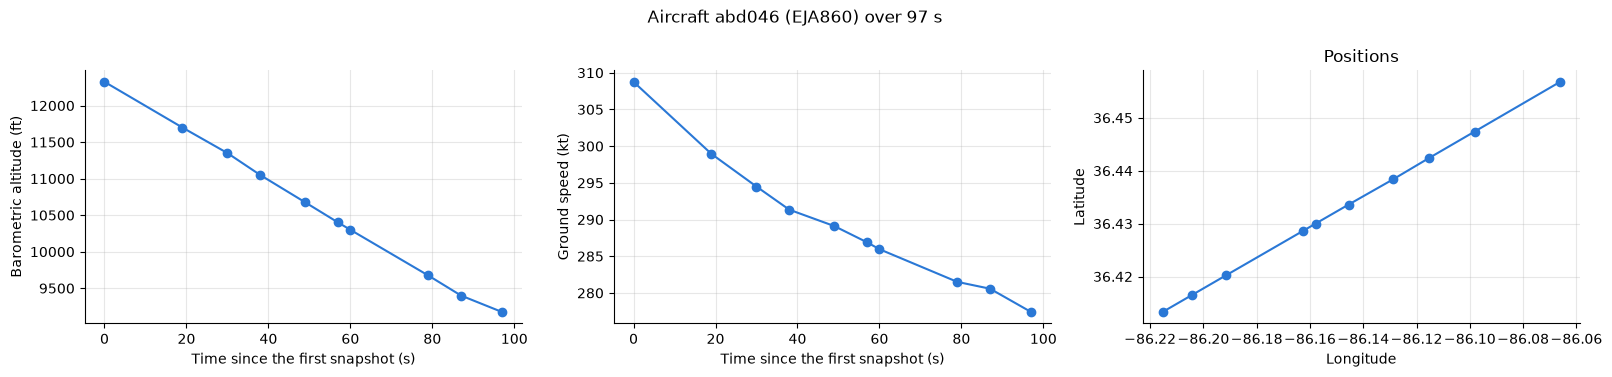

In [6]:
# Aircraft airborne in every distinct snapshot, with an altitude
distinct = all_states.drop_duplicates(["icao24", "snapshot_time"]).dropna(subset=["baro_altitude", "vertical_rate"])
n_snapshots = distinct["snapshot_time"].nunique()
followed = distinct.groupby("icao24").filter(lambda d: len(d) == n_snapshots and not d["on_ground"].any())
print(f"{followed['icao24'].nunique():,} aircraft airborne in all the {n_snapshots} snapshots")

# One of them climbing or descending at about 2,000 ft/min, to see something move
mean_rate_ft_min = followed.groupby("icao24")["vertical_rate"].mean() * MS_TO_FT_MIN
target = (mean_rate_ft_min.abs() - 2_000).abs().idxmin()
trajectory = followed[followed["icao24"] == target].sort_values("snapshot_time")
seconds = trajectory["snapshot_time"] - trajectory["snapshot_time"].iloc[0]
display(trajectory[["snapshot_time", "callsign", "latitude", "longitude", "baro_altitude", "velocity", "vertical_rate"]])

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].plot(seconds, trajectory["baro_altitude"] * M_TO_FT, marker="o")
axes[0].set_ylabel("Barometric altitude (ft)")
axes[1].plot(seconds, trajectory["velocity"] * MS_TO_KT, marker="o")
axes[1].set_ylabel("Ground speed (kt)")
for ax in axes[:2]:
    ax.set_xlabel("Time since the first snapshot (s)")
axes[2].plot(trajectory["longitude"], trajectory["latitude"], marker="o")
axes[2].set_xlabel("Longitude")
axes[2].set_ylabel("Latitude")
axes[2].set_title("Positions")
fig.suptitle(f"Aircraft {target} ({trajectory['callsign'].iloc[0].strip()}) over {seconds.iloc[-1]} s")
plt.tight_layout()
plt.show()

Most aircraft (about 10,700) are seen in every snapshot, so they can be followed. This one is descending at about 2,000 ft/min and slowing down: in 97 seconds it loses 3,100 ft and 30 kt, along a straight line. The trajectory is clean, but building trajectories this way only works **from now on**: following a whole day of flights would mean querying the API every 10 seconds for 24 hours (within a limited daily number of requests), with no way to look back.

## 3. Flights: `/flights/all`

A state vector does not say which **flight** it belongs to, nor where the aircraft comes from or goes to. OpenSky also builds a flight table: for each flight, the aircraft, the first and last times it was seen, and the departure and arrival airports **estimated** from the trajectory.

This endpoint needs an OpenSky account: the client id and secret are exchanged for a temporary access token (OAuth2 *client credentials* flow), sent with every request. The flights are computed once a day, during the night, so the most recent ones are those of the previous day. A request covers at most 2 hours: here, 16:00 to 18:00 UTC yesterday.

In [7]:
load_dotenv(PROJECT_DIR / ".env")
token_response = requests.post(TOKEN_URL, timeout=60, data={
    "grant_type": "client_credentials",
    "client_id": os.getenv("OPENSKY_CLIENT_ID"),
    "client_secret": os.getenv("OPENSKY_CLIENT_SECRET"),
})
token_response.raise_for_status()
headers = {"Authorization": f"Bearer {token_response.json()['access_token']}"}

day = datetime.now(timezone.utc).date() - timedelta(days=1)
begin = datetime(day.year, day.month, day.day, 16, tzinfo=timezone.utc)
end = begin + timedelta(hours=2)
flights = pd.DataFrame(get_json("flights/all", headers=headers,
                                params={"begin": int(begin.timestamp()), "end": int(end.timestamp())}))
print(f"{len(flights):,} flights between {begin:%Y-%m-%d %H:%M} and {end:%H:%M} UTC")
display(flights.head(3))

4,883 flights between 2026-10-11 16:00 and 18:00 UTC


,icao24,firstSeen,estDepartureAirport,lastSeen,estArrivalAirport,callsign,estDepartureAirportHorizDistance,estDepartureAirportVertDistance,estArrivalAirportHorizDistance,estArrivalAirportVertDistance,departureAirportCandidatesCount,arrivalAirportCandidatesCount
0,ab2fca,1791735728,KIWS,1791739640,KIWS,N82PC,945.0,19.0,1703.0,65.0,1,16
1,abd204,1791738240,KSAN,1791741057,KPHX,SWA3344,284.0,55.0,660.0,27.0,2,10
2,abdd1c,1791737882,K7T7,1791741348,KIAH,ASH4011,7934.0,807.0,2780.0,31.0,2,6


Share of missing values:


,firstSeen,lastSeen,estDepartureAirport,estArrivalAirport,callsign
missing share,0.0,0.0,0.161,0.111,0.002


Flights with both estimated airports: 75%, of which with the same departure and arrival airport: 17%


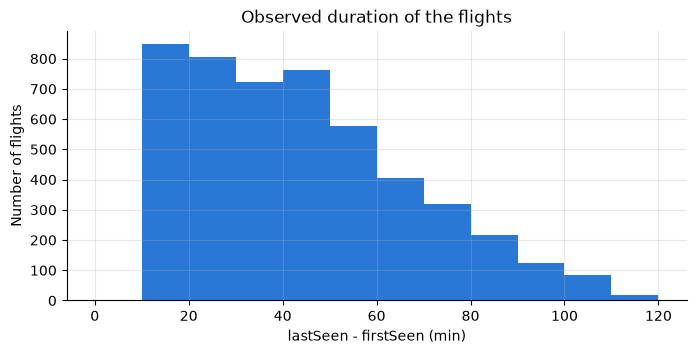

In [8]:
flights["duration_min"] = (flights["lastSeen"] - flights["firstSeen"]) / 60
print("Share of missing values:")
display(flights[["firstSeen", "lastSeen", "estDepartureAirport", "estArrivalAirport", "callsign"]]
        .isna().mean().round(3).to_frame("missing share").T)
both = flights.dropna(subset=["estDepartureAirport", "estArrivalAirport"])
print(f"Flights with both estimated airports: {len(both) / len(flights):.0%}, "
      f"of which with the same departure and arrival airport: {(both['estDepartureAirport'] == both['estArrivalAirport']).mean():.0%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(flights["duration_min"], bins=np.arange(0, flights["duration_min"].max() + 10, 10))
ax.set_xlabel("lastSeen - firstSeen (min)")
ax.set_ylabel("Number of flights")
ax.set_title("Observed duration of the flights")
plt.show()

- **The estimated airports are often missing:** 16 % of the flights have no departure airport, 11 % no arrival airport; only 75 % have both.
- **17 % of these flights depart from and arrive at the same airport:** local flights (training, sightseeing), or returns to the departure airport. For them, the "distance to the arrival airport" does not describe the flight.
- **Every flight returned lasts between 10 minutes and 2 hours:** a request only returns the flights that start and end within its interval, which is limited to 2 hours. A long-haul flight can never appear in such a request.

## 4. A whole flight: `/tracks/all`, and a first label

The track of a flight is requested with the aircraft (`icao24`) and any time during the flight. A commercial flight is chosen (a callsign made of an airline code and a number, both airports known and different), the longest of the interval.

In [9]:
airline = flights["callsign"].fillna("").str.strip().str.match(r"^[A-Z]{3}\d")
candidates = flights[airline].dropna(subset=["estDepartureAirport", "estArrivalAirport"])
candidates = candidates[candidates["estDepartureAirport"] != candidates["estArrivalAirport"]]
flight = candidates.loc[candidates["duration_min"].idxmax()]
print(f"Flight {flight['callsign'].strip()} ({flight['icao24']}): {flight['estDepartureAirport']} -> "
      f"{flight['estArrivalAirport']}, from {to_utc(flight['firstSeen']):%H:%M} to {to_utc(flight['lastSeen']):%H:%M} UTC")

track = get_json("tracks/all", headers=headers,
                 params={"icao24": flight["icao24"], "time": int((flight["firstSeen"] + flight["lastSeen"]) / 2)})
print(f"Keys of the response: {list(track)}")
path = pd.DataFrame(track["path"], columns=["time", "latitude", "longitude", "baro_altitude", "true_track", "on_ground"])
gaps = path["time"].diff().dropna()
print(f"{len(path)} points over {(path['time'].iloc[-1] - path['time'].iloc[0]) / 60:.0f} min; "
      f"time between two points: median {gaps.median():.0f} s, max {gaps.max():.0f} s")
print(f"Distinct altitudes in the track (ft): {np.unique(np.round(path['baro_altitude'] * M_TO_FT, -1))[:12]}...")
display(path.head())

Flight SKW3876 (a25925): KDEN -> KAUS, from 16:00 to 17:58 UTC


Keys of the response: ['icao24', 'callsign', 'startTime', 'endTime', 'path']
172 points over 118 min; time between two points: median 5 s, max 1921 s
Distinct altitudes in the track (ft): [    0.  1000.  2000.  3000.  4000.  5000.  6000.  8000.  9000. 10000.
 11000. 12000.]...


,time,latitude,longitude,baro_altitude,true_track,on_ground
0,1791734453,39.8318,-104.6418,1524,180,False
1,1791734465,39.8221,-104.6420,1828,181,False
2,1791734506,39.7868,-104.6428,1828,180,False
3,1791734538,39.7556,-104.6430,2438,180,False
4,1791734594,39.6935,-104.6436,2743,180,False


- **The track is a simplified trajectory, not the raw state vectors:** the altitudes are rounded to the nearest 1,000 ft, and the points are dense in the climb and the descent but very sparse in the cruise (up to 32 minutes between two points).
- **The track starts at the departure and ends at the arrival:** about 5,000 ft at Denver (the airport is at ~5,400 ft) and 0 ft at Austin, the rounding hiding the exact elevations.

Last point of the track vs lastSeen: 1 s


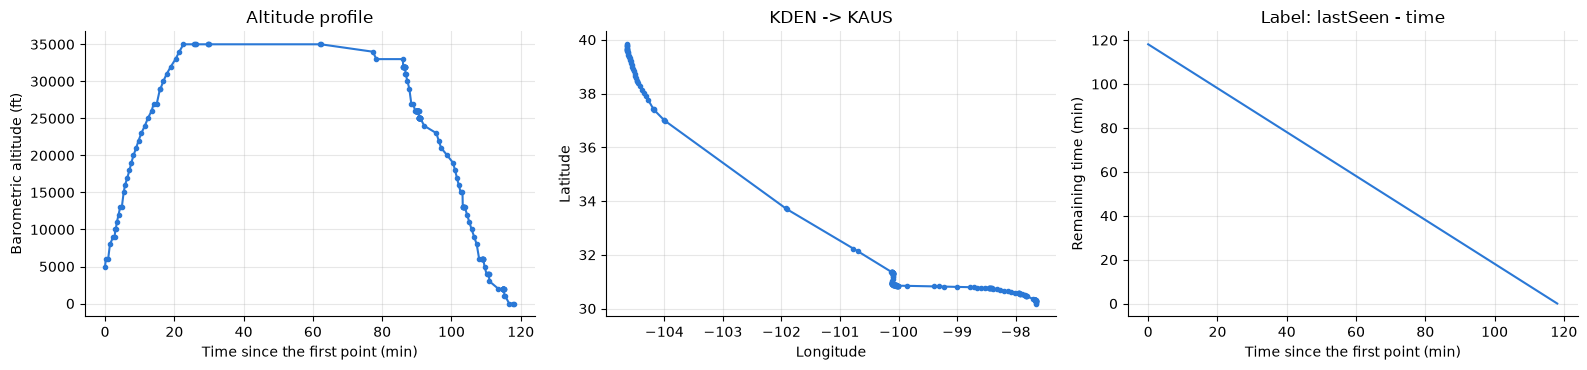

In [10]:
# First label: the time left before the end of the flight (lastSeen)
path["remaining_time_min"] = (flight["lastSeen"] - path["time"]) / 60
minutes = (path["time"] - path["time"].iloc[0]) / 60
print(f"Last point of the track vs lastSeen: {flight['lastSeen'] - path['time'].iloc[-1]:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].plot(minutes, path["baro_altitude"] * M_TO_FT, marker=".")
axes[0].set_xlabel("Time since the first point (min)")
axes[0].set_ylabel("Barometric altitude (ft)")
axes[0].set_title("Altitude profile")
axes[1].plot(path["longitude"], path["latitude"], marker=".")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_title(f"{flight['estDepartureAirport']} -> {flight['estArrivalAirport']}")
axes[2].plot(minutes, path["remaining_time_min"])
axes[2].set_xlabel("Time since the first point (min)")
axes[2].set_ylabel("Remaining time (min)")
axes[2].set_title("Label: lastSeen - time")
plt.tight_layout()
plt.show()

The flight is complete from the take-off at Denver to the landing at Austin: climb, cruise at 35,000 ft, descent. The last point of the track is 1 second before `lastSeen`, so `lastSeen` is a good estimate of the end of the flight, and the **remaining time** can be defined for every point as `lastSeen - time`: the quantity this project tries to predict (notebook 02 refines it slightly: the time of the last airborne state vector instead of `lastSeen`). By construction, it decreases by exactly one minute per minute; what makes it hard to predict is that at a given moment, the model only sees the current state of the aircraft, not the rest of the flight.

## 5. Conclusions

**What the data looks like.** A state vector is a few values broadcast by an aircraft: its identity, position, two altitudes, speed, direction and vertical rate, in SI units. The flights are a separate table, with the time window of each flight and its estimated departure and arrival airports. The remaining time can be defined from the end of the flight.

**What it implies for the pipeline (notebook 02):**
- the state vectors have no flight identifier: they must be **matched to the flights** through the aircraft (`icao24`) and the time window `[firstSeen, lastSeen]`;
- the points **on the ground** and the points with **missing values** must be removed, and the units converted (feet, knots, ft/min);
- the **estimated airports** are often missing, sometimes identical: the flights without a usable destination must be dropped;
- the **coverage has gaps** (oceans, some continents): a flight can disappear for a while.

**Why the REST API is not enough.** It is made for live use, not for building a dataset:
- `/states/all` only gives the present (a snapshot every ~10 seconds), with a limited number of requests per day;
- `/flights/all` covers at most 2 hours per request, and only returns the flights that start and end within this interval: no long-haul flights;
- `/tracks/all` gives one flight per request, simplified (altitudes rounded to 1,000 ft, few points in cruise), and only for the last 30 days.

The next notebooks therefore use the **public datasets of the OpenSky Network**, exported from its historical database (whose direct access through Trino is reserved to researchers): the table `state_vectors_data4` gives one state vector per aircraft and per second, and `flights_data4` the flights, for a past day. One full day (2026-03-01, ~12 GB) is the starting point of notebook 02.